# Case Studies: IRIS and Handwritten Digits

This notebook is a lab-style case study. It applies the workflow from `m1a_ml_workflow` to two
classic datasets:

1. **IRIS:** 150 flowers, four measurements, three species.
2. **Handwritten digits:** 1,797 images, 64 pixel features, ten digit classes.

The goal is not to find the single "best" algorithm. The goal is to practise a reliable process:

- inspect the data before modelling;
- split honestly and stratify;
- put preprocessing inside a pipeline;
- compare models with cross-validation;
- touch the test set once;
- inspect errors, not only accuracy;
- explain what the results do and do not show.

## Learning objectives

By the end of this notebook you can:

- run an end-to-end classification case study;
- compare a baseline, linear model, distance-based model, tree, forest, and SVM;
- interpret cross-validation results and a held-out test set;
- read a confusion matrix and classification report;
- use PCA for exploration without leaking test information;
- describe the limitations of a high score on a clean benchmark dataset.

In [1]:
import os
import warnings

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")
warnings.filterwarnings("ignore", message="A NumPy version")
warnings.filterwarnings("ignore", message="Could not find the number of physical cores")
warnings.filterwarnings("ignore", category=UserWarning, module="joblib")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits, load_iris
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 4)
np.set_printoptions(precision=3, suppress=True)

## 1. A reusable comparison function

The function below does four things for each candidate model:

1. runs stratified cross-validation on the training data;
2. reports mean accuracy and mean macro F1;
3. refits the model on the full training set;
4. evaluates once on the held-out test set.

The test set is not used for model selection. This separation is the main defence against
optimistic results.

In [2]:
def compare_classifiers(models, X_train, y_train, X_test, y_test, cv_splits=5):
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42)
    rows = []
    fitted = {}

    for name, model in models.items():
        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=["accuracy", "f1_macro"],
        )
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        rows.append(
            {
                "model": name,
                "cv_accuracy": scores["test_accuracy"].mean(),
                "cv_accuracy_std": scores["test_accuracy"].std(),
                "cv_macro_f1": scores["test_f1_macro"].mean(),
                "test_accuracy": accuracy_score(y_test, predictions),
                "test_macro_f1": f1_score(y_test, predictions, average="macro"),
            }
        )
        fitted[name] = model

    table = (
        pd.DataFrame(rows)
        .sort_values(["cv_macro_f1", "cv_accuracy"], ascending=False)
        .reset_index(drop=True)
    )
    return table, fitted

## 2. Case study 1: IRIS

IRIS is small, clean, balanced, and low-dimensional. That makes it excellent for learning the
workflow, but it is not representative of messy real-world data. Many models can score very high,
so differences between them are often small and sensitive to the split.

In [3]:
iris = load_iris(as_frame=True)
iris_df = iris.frame.copy()
iris_df["species"] = iris_df["target"].map(dict(enumerate(iris.target_names)))

print(f"Rows: {iris_df.shape[0]}, columns: {iris_df.shape[1]}")
print(f"Features: {iris.feature_names}")
print(f"Classes: {[str(name) for name in iris.target_names]}")
print("\nClass counts:")
print(iris_df["species"].value_counts().to_string())
print("\nFirst rows:")
print(iris_df.head().to_string(index=False))

Rows: 150, columns: 6
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa', 'versicolor', 'virginica']

Class counts:
species
setosa        50
versicolor    50
virginica     50

First rows:
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target species
               5.1               3.5                1.4               0.2       0  setosa
               4.9               3.0                1.4               0.2       0  setosa
               4.7               3.2                1.3               0.2       0  setosa
               4.6               3.1                1.5               0.2       0  setosa
               5.0               3.6                1.4               0.2       0  setosa


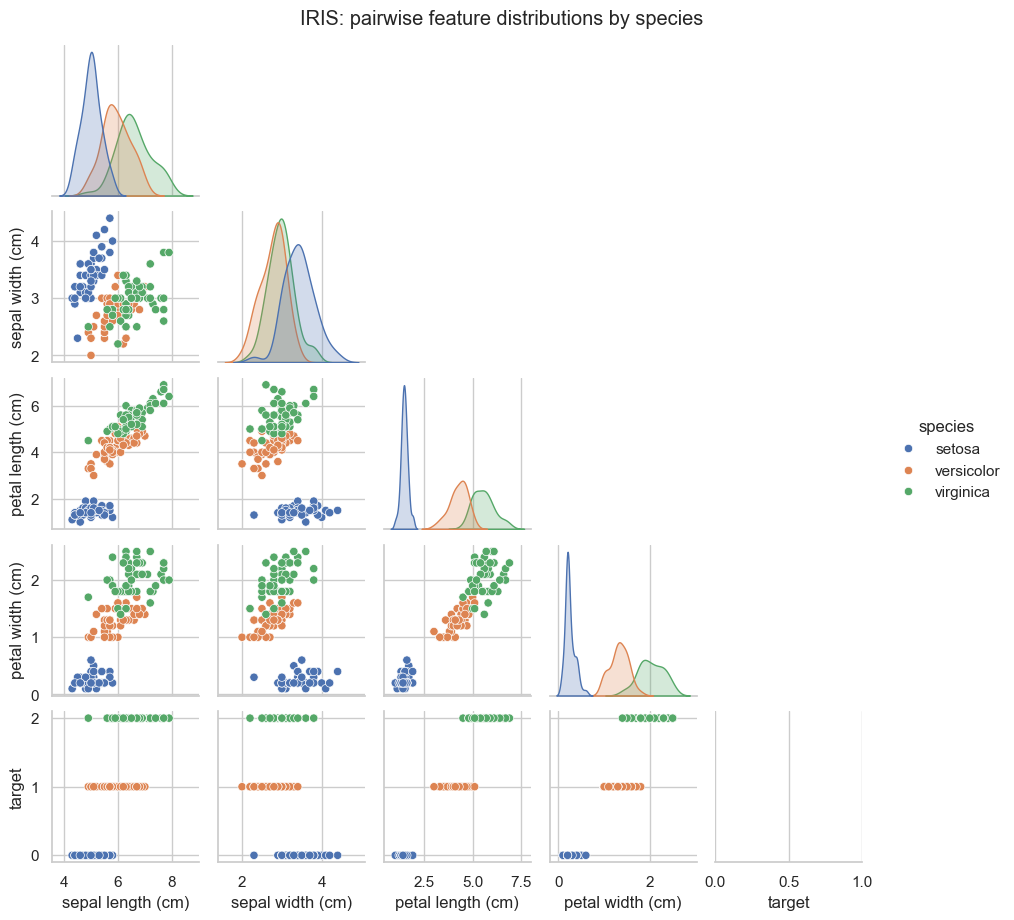

In [4]:
sns.pairplot(iris_df, hue="species", corner=True, diag_kind="kde", height=1.8)
plt.suptitle("IRIS: pairwise feature distributions by species", y=1.02)
plt.show()

In [5]:
class_means = iris_df.groupby("species")[iris.feature_names].mean().round(2)
print(class_means.to_string())

            sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
species                                                                             
setosa                   5.01              3.43               1.46              0.25
versicolor               5.94              2.77               4.26              1.33
virginica                6.59              2.97               5.55              2.03


The pairplot already suggests that petal length and petal width separate the species much better
than sepal measurements. In a real project this observation would guide feature selection and the
choice of a simple baseline.

In [6]:
X_iris = iris.data
y_iris = iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_iris,
    y_iris,
    test_size=0.30,
    stratify=y_iris,
    random_state=42,
)

iris_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=42)),
        ]
    ),
    "k-NN (k=5)": Pipeline(
        [("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=5))]
    ),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "SVM (RBF)": Pipeline(
        [("scaler", StandardScaler()), ("model", SVC(kernel="rbf", random_state=42))]
    ),
}

iris_table, iris_fitted = compare_classifiers(
    iris_models,
    X_train_i,
    y_train_i,
    X_test_i,
    y_test_i,
)

print("IRIS model comparison (test set kept out of model selection)")
print(iris_table.round(3).to_string(index=False))

IRIS model comparison (test set kept out of model selection)
                  model  cv_accuracy  cv_accuracy_std  cv_macro_f1  test_accuracy  test_macro_f1
    Logistic regression        0.981            0.023        0.981          0.911          0.911
              SVM (RBF)        0.971            0.038        0.971          0.933          0.933
Decision tree (depth 3)        0.952            0.043        0.952          0.978          0.978
          Random forest        0.952            0.043        0.952          0.911          0.911
             k-NN (k=5)        0.933            0.049        0.933          0.911          0.910
      Majority baseline        0.333            0.000        0.167          0.333          0.167


The table is sorted by cross-validation macro F1. The test columns are shown for the final check,
not for selection. The baseline is near 0.33 because there are three balanced classes. Any useful
model must beat it substantially. With only 45 test observations, one error changes accuracy by
about 2.2 percentage points, so cross-validation is a more stable comparison than a single split.

IRIS model selected by CV macro F1: Logistic regression

Classification report:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45



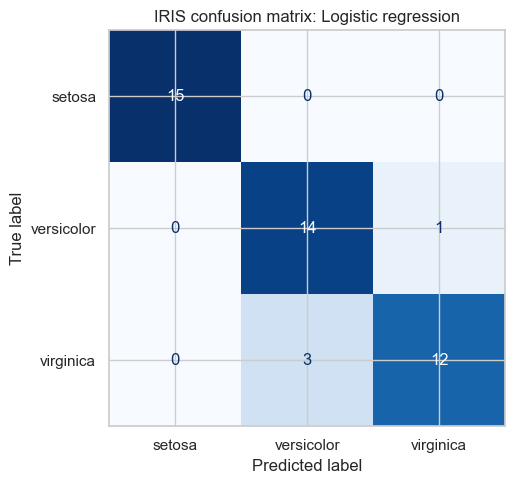

In [7]:
best_iris_name = iris_table.loc[0, "model"]
best_iris = iris_fitted[best_iris_name]
iris_pred = best_iris.predict(X_test_i)

print(f"IRIS model selected by CV macro F1: {best_iris_name}")
print("\nClassification report:")
print(
    classification_report(
        y_test_i,
        iris_pred,
        target_names=iris.target_names,
        digits=3,
    )
)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test_i,
    iris_pred,
    display_labels=iris.target_names,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"IRIS confusion matrix: {best_iris_name}")
plt.tight_layout()
plt.show()

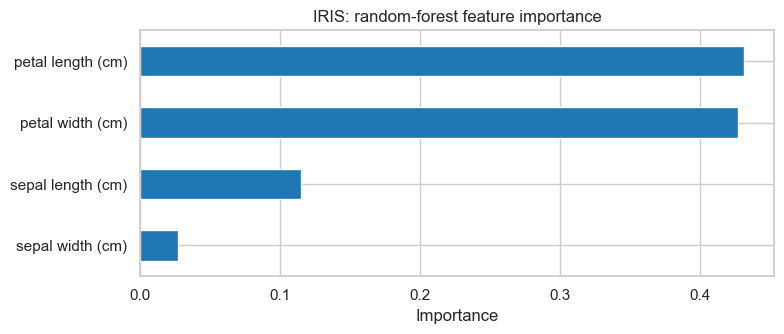

In [8]:
rf_iris = iris_fitted["Random forest"]
importances = (
    pd.Series(rf_iris.feature_importances_, index=iris.feature_names)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 3.5))
importances.plot.barh(ax=ax, color="tab:blue")
ax.set_title("IRIS: random-forest feature importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

Feature importance describes how much this fitted forest used each feature. It is not a causal
effect, and correlated features can share importance unpredictably. Still, it is consistent with
the pairplot: petal measurements carry most of the signal.

In [9]:
iris_errors = X_test_i.copy()
iris_errors["actual"] = iris.target_names[y_test_i]
iris_errors["predicted"] = iris.target_names[iris_pred]
iris_errors = iris_errors[iris_errors["actual"] != iris_errors["predicted"]]

if iris_errors.empty:
    print("No IRIS test errors for this model and split.")
else:
    print("Misclassified IRIS test rows:")
    print(iris_errors.to_string(index=False))

Misclassified IRIS test rows:
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)     actual  predicted
               6.3               2.8                5.1               1.5  virginica versicolor
               6.1               2.6                5.6               1.4  virginica versicolor
               6.7               3.0                5.0               1.7 versicolor  virginica
               4.9               2.5                4.5               1.7  virginica versicolor


The IRIS test score is lower than the cross-validation score, which is a useful reminder that a
single small test set is noisy. The decision tree happened to score higher on this test split, but
it was not selected because that would mean using the test set to choose the model. The relevant
lesson is the process: baseline, pipeline, cross-validation, held-out test, and error inspection.

## 3. Case study 2: handwritten digits

The digits dataset is larger and much higher-dimensional: each 8 x 8 image becomes 64 pixel
features. It is still clean and balanced, but the classes overlap more than IRIS and the problem is
genuinely nonlinear.

In [10]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target
digits_labels = [str(digit) for digit in digits.target_names]

print(f"Feature matrix: {X_digits.shape}")
print(f"Images: {digits.images.shape}")
print(f"Classes: {digits_labels}")
print("\nClass counts:")
print(pd.Series(y_digits).value_counts().sort_index().to_string())

Feature matrix: (1797, 64)
Images: (1797, 8, 8)
Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

Class counts:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180


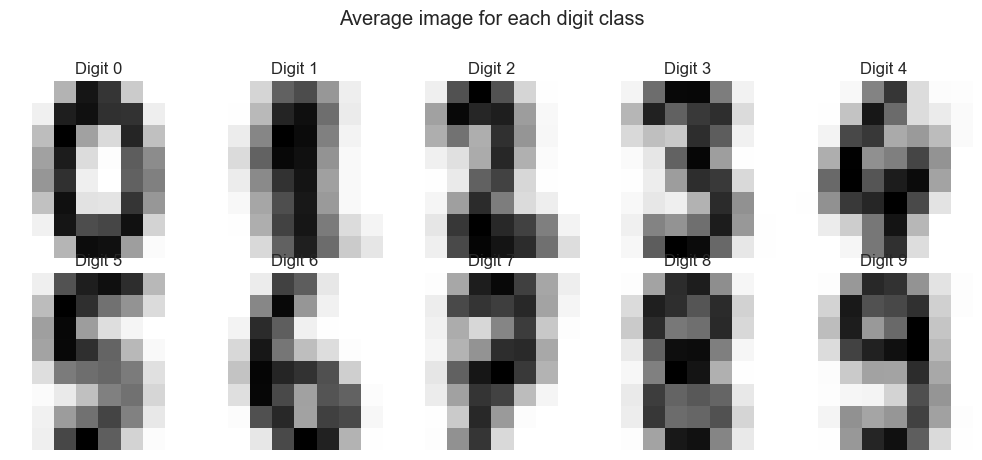

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit, ax in enumerate(axes.ravel()):
    mean_image = digits.images[y_digits == digit].mean(axis=0)
    ax.imshow(mean_image, cmap="gray_r")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.suptitle("Average image for each digit class", y=1.02)
plt.tight_layout()
plt.show()

The average images already show why some digits are easier than others. A 0 and an 8 share a closed
loop; a 3, 5, and 9 share curved strokes. The model must learn from pixel combinations, not from a
single pixel.

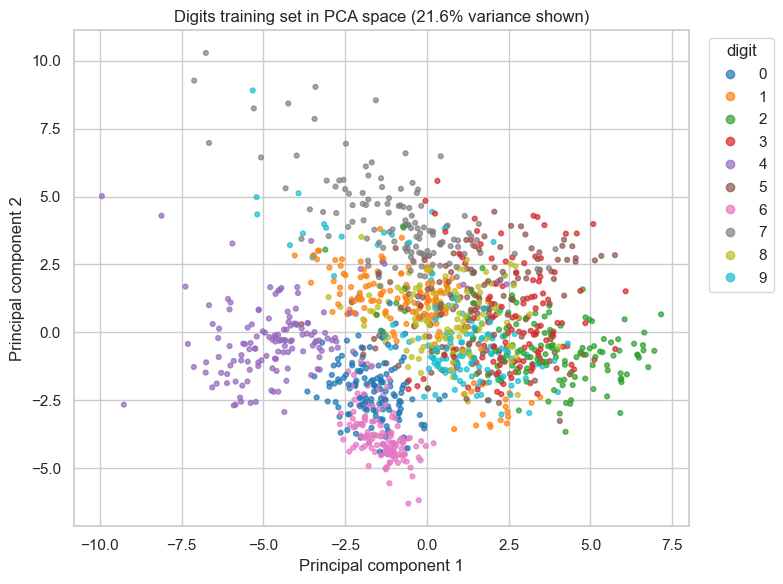

In [12]:
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_digits,
    y_digits,
    test_size=0.25,
    stratify=y_digits,
    random_state=42,
)

pca_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=2, random_state=42)),
    ]
)
X_train_pca = pca_pipeline.fit_transform(X_train_d)
explained = pca_pipeline.named_steps["pca"].explained_variance_ratio_.sum()

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train_d,
    cmap="tab10",
    s=12,
    alpha=0.7,
)
handles, labels = scatter.legend_elements()
ax.legend(handles, labels, title="digit", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title(f"Digits training set in PCA space ({explained:.1%} variance shown)")
plt.tight_layout()
plt.show()

PCA is fitted on the training data only and then applied to the test data. This is a visualization,
not a classifier. Two components capture only part of the variance, so overlapping clusters do not
mean the classes are inseparable in the full 64-dimensional space.

In [13]:
digits_models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=42)),
        ]
    ),
    "k-NN (k=5)": Pipeline(
        [("scaler", StandardScaler()), ("model", KNeighborsClassifier(n_neighbors=5))]
    ),
    "Decision tree (depth 10)": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "SVM (RBF)": Pipeline(
        [("scaler", StandardScaler()), ("model", SVC(kernel="rbf", random_state=42))]
    ),
}

digits_table, digits_fitted = compare_classifiers(
    digits_models,
    X_train_d,
    y_train_d,
    X_test_d,
    y_test_d,
)

print("Digits model comparison (test set kept out of model selection)")
print(digits_table.round(3).to_string(index=False))

Digits model comparison (test set kept out of model selection)
                   model  cv_accuracy  cv_accuracy_std  cv_macro_f1  test_accuracy  test_macro_f1
               SVM (RBF)        0.979            0.005        0.979          0.980          0.980
           Random forest        0.978            0.011        0.978          0.967          0.966
              k-NN (k=5)        0.975            0.005        0.975          0.964          0.964
     Logistic regression        0.966            0.010        0.966          0.978          0.978
Decision tree (depth 10)        0.843            0.021        0.842          0.836          0.836
       Majority baseline        0.100            0.000        0.018          0.102          0.019


The table is sorted by cross-validation macro F1. Distance-based and kernel models usually do well
here because scaling puts pixel features on a common footing and the class boundaries are
nonlinear. The decision tree is interpretable but usually weaker; the forest improves on it by
averaging many trees.

Digits model selected by CV macro F1: SVM (RBF)

Classification report:
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.957     0.978     0.968        46
           2      1.000     1.000     1.000        44
           3      1.000     1.000     1.000        46
           4      0.957     0.978     0.967        45
           5      0.978     0.978     0.978        46
           6      0.978     1.000     0.989        45
           7      0.957     0.978     0.967        45
           8      1.000     0.930     0.964        43
           9      0.977     0.956     0.966        45

    accuracy                          0.980       450
   macro avg      0.980     0.980     0.980       450
weighted avg      0.980     0.980     0.980       450



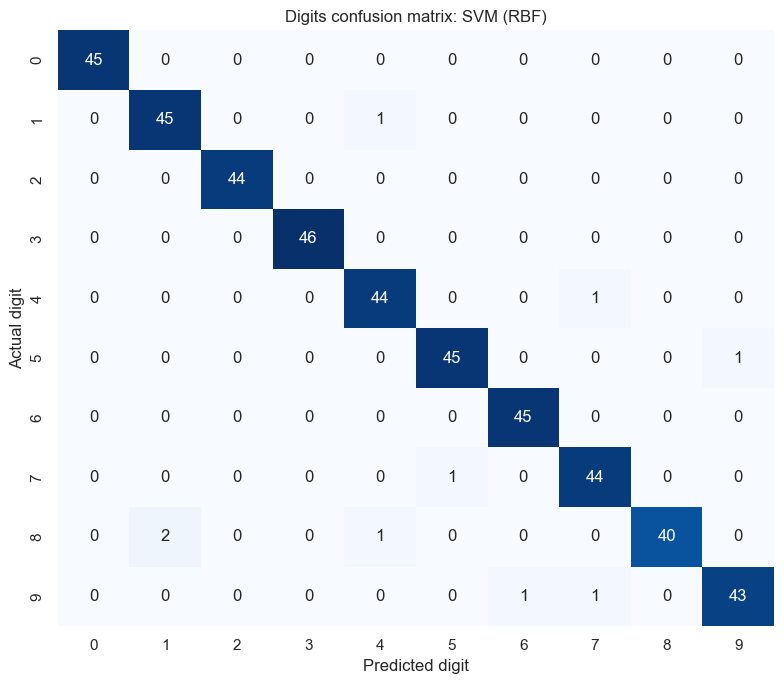

In [14]:
best_digits_name = digits_table.loc[0, "model"]
best_digits = digits_fitted[best_digits_name]
digits_pred = best_digits.predict(X_test_d)

print(f"Digits model selected by CV macro F1: {best_digits_name}")
print("\nClassification report:")
print(
    classification_report(
        y_test_d,
        digits_pred,
        target_names=digits_labels,
        digits=3,
    )
)

cm = confusion_matrix(y_test_d, digits_pred)
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=digits_labels,
    yticklabels=digits_labels,
    ax=ax,
)
ax.set_xlabel("Predicted digit")
ax.set_ylabel("Actual digit")
ax.set_title(f"Digits confusion matrix: {best_digits_name}")
plt.tight_layout()
plt.show()

Misclassified digits: 9 of 450


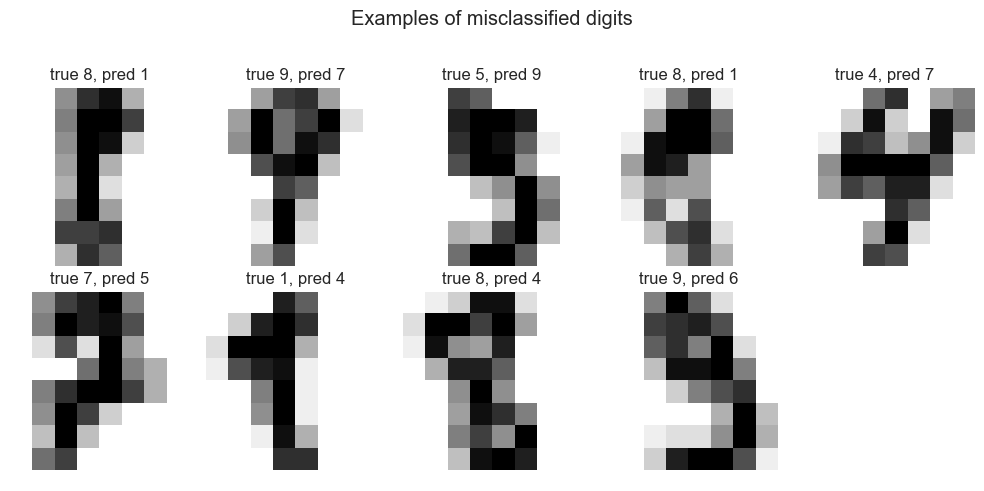

In [15]:
wrong = np.where(digits_pred != y_test_d)[0]
print(f"Misclassified digits: {len(wrong)} of {len(y_test_d)}")

if len(wrong) == 0:
    print("No test errors for this model and split.")
else:
    fig, axes = plt.subplots(2, 5, figsize=(10, 4.8))
    for ax, idx in zip(axes.ravel(), wrong[:10]):
        ax.imshow(X_test_d[idx].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"true {y_test_d[idx]}, pred {digits_pred[idx]}")
        ax.axis("off")
    for ax in axes.ravel()[len(wrong[:10]) :]:
        ax.axis("off")
    plt.suptitle("Examples of misclassified digits", y=1.02)
    plt.tight_layout()
    plt.show()

Error analysis is more informative than a single accuracy number. Look for systematic confusions,
such as 3 versus 5, 4 versus 9, or 7 versus 1. Those patterns suggest better features, more data,
or a model that can represent the relevant shape differences.

## 4. What the two case studies teach

### IRIS

- Small, balanced, clean, low-dimensional data can make many models look excellent.
- A single held-out split is unstable when the test set is small.
- Petal measurements dominate; feature importance agrees with the exploratory plots.
- A perfect score is a property of the benchmark, not proof of a production-ready model.

### Digits

- Higher dimensionality and nonlinear boundaries reward scaling, k-NN, and kernel SVM.
- Accuracy can hide class-specific errors; the confusion matrix exposes them.
- PCA is useful for exploration, but two components do not preserve all class information.
- The best model on this split is not guaranteed to be the best on a different split or dataset.

### Shared workflow

1. Inspect class balance and feature scales.
2. Establish a majority-class baseline.
3. Split with stratification.
4. Put all preprocessing inside a pipeline.
5. Compare with cross-validation.
6. Evaluate once on the test set.
7. Read the confusion matrix and classification report.
8. Inspect individual errors.
9. State limitations and next steps.

## 5. Lab tasks

1. Change the IRIS test size to 0.20 and the random state to 7. Does the model ranking change?
2. Remove `StandardScaler` from the k-NN and SVM pipelines. Compare cross-validation accuracy.
3. Tune `n_neighbors` for k-NN and `C`/`gamma` for the RBF SVM with `GridSearchCV` inside the
   pipeline. Report the best parameters and CV score.
4. Add `PCA(n_components=0.95)` before each digits classifier. Compare accuracy and fit time with
   the full feature set.
5. Inspect five misclassified digits and describe the visual similarity that may explain each error.
6. Use the digits classification report to identify the weakest class by F1. Propose one data or
   feature change that might help.
7. Repeat the digits comparison with a different `random_state`. How stable are the top models?
8. Write a one-page case-study report with a comparison table, one confusion matrix, an error
   analysis, and a limitations section.

## Key takeaways

- A clean benchmark is a teaching tool, not a deployment test.
- Cross-validation supports model selection; the test set supports the final claim.
- Accuracy is not enough: inspect macro F1, per-class recall, and the confusion matrix.
- Pipelines prevent preprocessing leakage.
- Error analysis turns a score into an explanation.
- Always report what the data and the evaluation do not cover.